# 🎯 Notebook 3: Multi-Class Stimulus Classification (SVM & KNN)

## 1. Scientific Objective
Classify multi-class stimulus states (`normal`, `music`, `water`, `dead`).
All generated plots are saved to `plot/03_multiclass_stimulus_svm_knn/`.


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.manifold import TSNE

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

NOTEBOOK_NAME = "03_multiclass_stimulus_svm_knn"
if os.path.basename(os.getcwd()) == "notebook":
    PLOT_DIR = os.path.join("..", "plot", NOTEBOOK_NAME)
    DATA_PATH = "plant_time_series_features.csv"
else:
    PLOT_DIR = os.path.join("plot", NOTEBOOK_NAME)
    DATA_PATH = os.path.join("notebook", "plant_time_series_features.csv") if os.path.exists(os.path.join("notebook", "plant_time_series_features.csv")) else "plant_time_series_features.csv"

os.makedirs(PLOT_DIR, exist_ok=True)
print(f"Plots will be saved to: {os.path.abspath(PLOT_DIR)}")

df = pd.read_csv(DATA_PATH)
print("Classes:", df["main_category"].value_counts())


Plots will be saved to: C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\plot\03_multiclass_stimulus_svm_knn
Classes: main_category
music     2195
normal     963
water      341
dead        30
Name: count, dtype: int64


## 2. Standardized Scaling & Session Splits

In [2]:
feature_cols = [
    "mean", "std", "var", "min", "max", "range", "median", 
    "rms", "mad", "p25", "p75", "iqr", "zcr", "skew", "kurt", 
    "peak_count", "low_freq_power", "mid_freq_power", "high_freq_power", 
    "spectral_entropy", "dominant_freq"
]

class_labels = ["normal", "music", "water", "dead"]
label_to_idx = {l: i for i, l in enumerate(class_labels)}

X = df[feature_cols].values
y = df["main_category"].map(label_to_idx).values
groups = df["session_id"].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)


## 3. Train SVM (RBF Kernel) & KNN

In [3]:
svm_model = SVC(kernel='rbf', C=5.0, probability=True, random_state=42)
knn_model = KNeighborsClassifier(n_neighbors=7, weights='distance')

oof_preds_svm = np.zeros(len(y), dtype=int)
oof_proba_svm = np.zeros((len(y), len(class_labels)))
oof_preds_knn = np.zeros(len(y), dtype=int)

for fold, (tr_idx, te_idx) in enumerate(skf.split(X_scaled, y)):
    svm_model.fit(X_scaled[tr_idx], y[tr_idx])
    oof_preds_svm[te_idx] = svm_model.predict(X_scaled[te_idx])
    oof_proba_svm[te_idx] = svm_model.predict_proba(X_scaled[te_idx])
    
    knn_model.fit(X_scaled[tr_idx], y[tr_idx])
    oof_preds_knn[te_idx] = knn_model.predict(X_scaled[te_idx])

print("=== SVM (RBF) Report ===")
print(classification_report(y, oof_preds_svm, target_names=class_labels))
print("=== KNN (k=7) Report ===")
print(classification_report(y, oof_preds_knn, target_names=class_labels))


C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


C:\Users\asim\projects\others\PLANT-EMOTION-DETECTION\.venv\Lib\site-packages\sklearn\svm\_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


=== SVM (RBF) Report ===
              precision    recall  f1-score   support

      normal       0.91      0.89      0.90       963
       music       0.96      0.98      0.97      2195
       water       0.88      0.84      0.86       341
        dead       1.00      1.00      1.00        30

    accuracy                           0.94      3529
   macro avg       0.94      0.93      0.93      3529
weighted avg       0.94      0.94      0.94      3529

=== KNN (k=7) Report ===
              precision    recall  f1-score   support

      normal       0.93      0.91      0.92       963
       music       0.97      0.98      0.97      2195
       water       0.85      0.87      0.86       341
        dead       1.00      1.00      1.00        30

    accuracy                           0.95      3529
   macro avg       0.94      0.94      0.94      3529
weighted avg       0.95      0.95      0.95      3529



## 4. Multi-Class Normalized Confusion Matrices

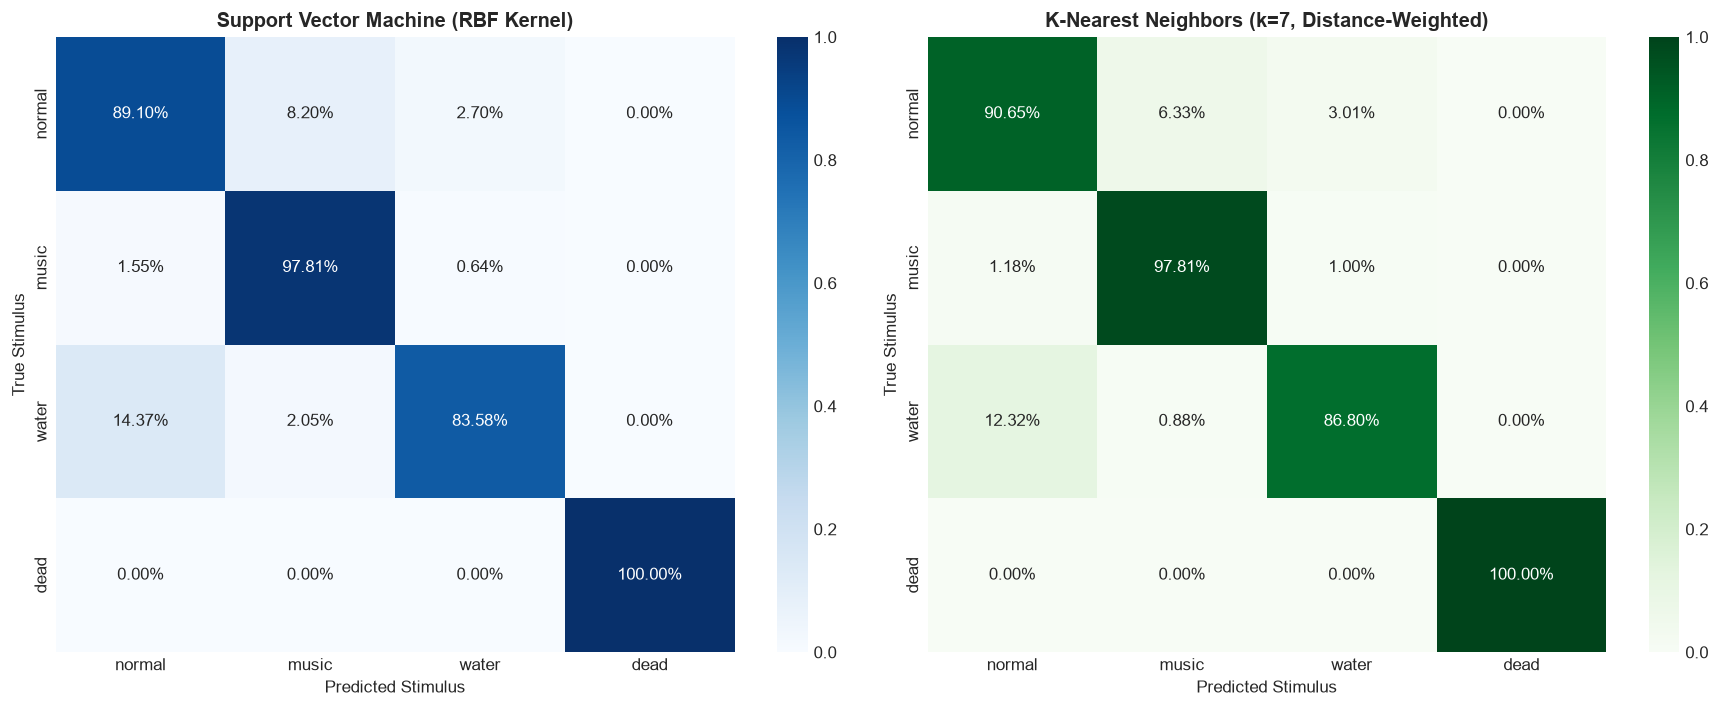

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

cm_svm = confusion_matrix(y, oof_preds_svm, normalize='true')
sns.heatmap(cm_svm, annot=True, fmt=".2%", cmap="Blues", ax=ax1, xticklabels=class_labels, yticklabels=class_labels)
ax1.set_title("Support Vector Machine (RBF Kernel)", fontweight='bold')
ax1.set_ylabel("True Stimulus")
ax1.set_xlabel("Predicted Stimulus")

cm_knn = confusion_matrix(y, oof_preds_knn, normalize='true')
sns.heatmap(cm_knn, annot=True, fmt=".2%", cmap="Greens", ax=ax2, xticklabels=class_labels, yticklabels=class_labels)
ax2.set_title("K-Nearest Neighbors (k=7, Distance-Weighted)", fontweight='bold')
ax2.set_ylabel("True Stimulus")
ax2.set_xlabel("Predicted Stimulus")

plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "1_multiclass_confusion_matrices.png"), dpi=300, bbox_inches='tight')
plt.show()


## 5. One-vs-Rest (OvR) ROC Curves

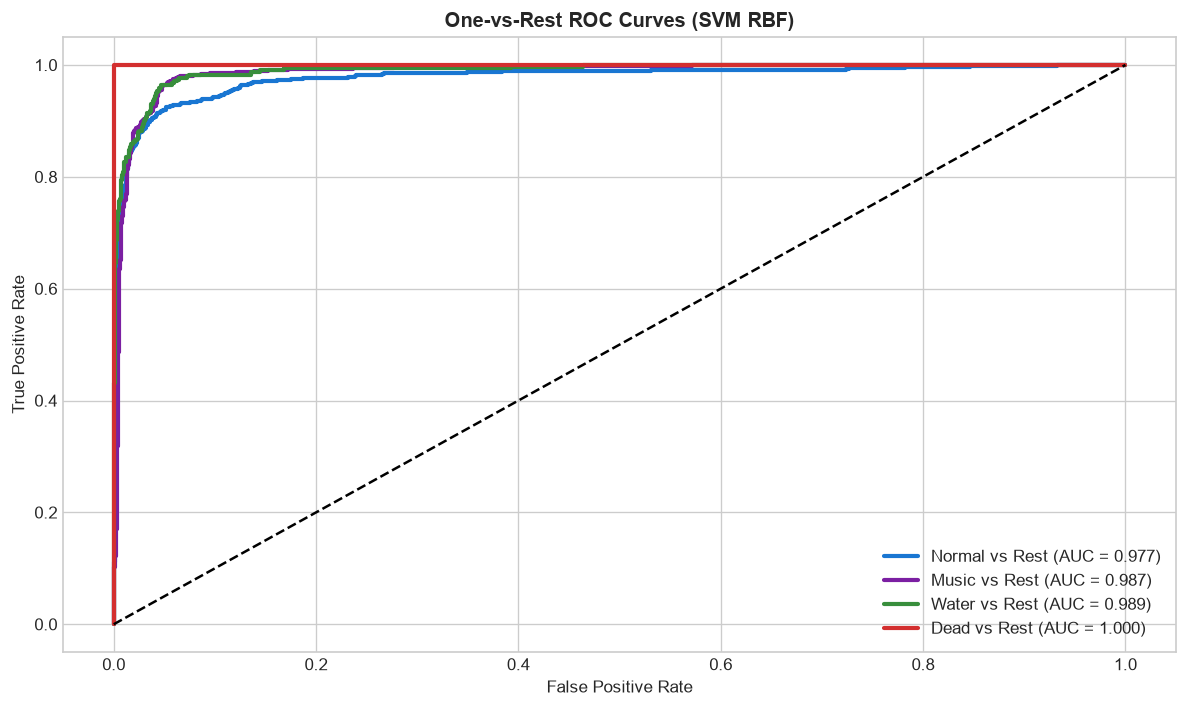

In [5]:
plt.figure(figsize=(10, 6))
colors = ["#1976D2", "#7B1FA2", "#388E3C", "#D32F2F"]

for i, (c_name, color) in enumerate(zip(class_labels, colors)):
    y_binary = (y == i).astype(int)
    fpr, tpr, _ = roc_curve(y_binary, oof_proba_svm[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2.5, label=f'{c_name.capitalize()} vs Rest (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1.5)
plt.title("One-vs-Rest ROC Curves (SVM RBF)", fontweight='bold')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "2_ovr_roc_curves.png"), dpi=300, bbox_inches='tight')
plt.show()


## 6. t-SNE 2D Manifold Visualization

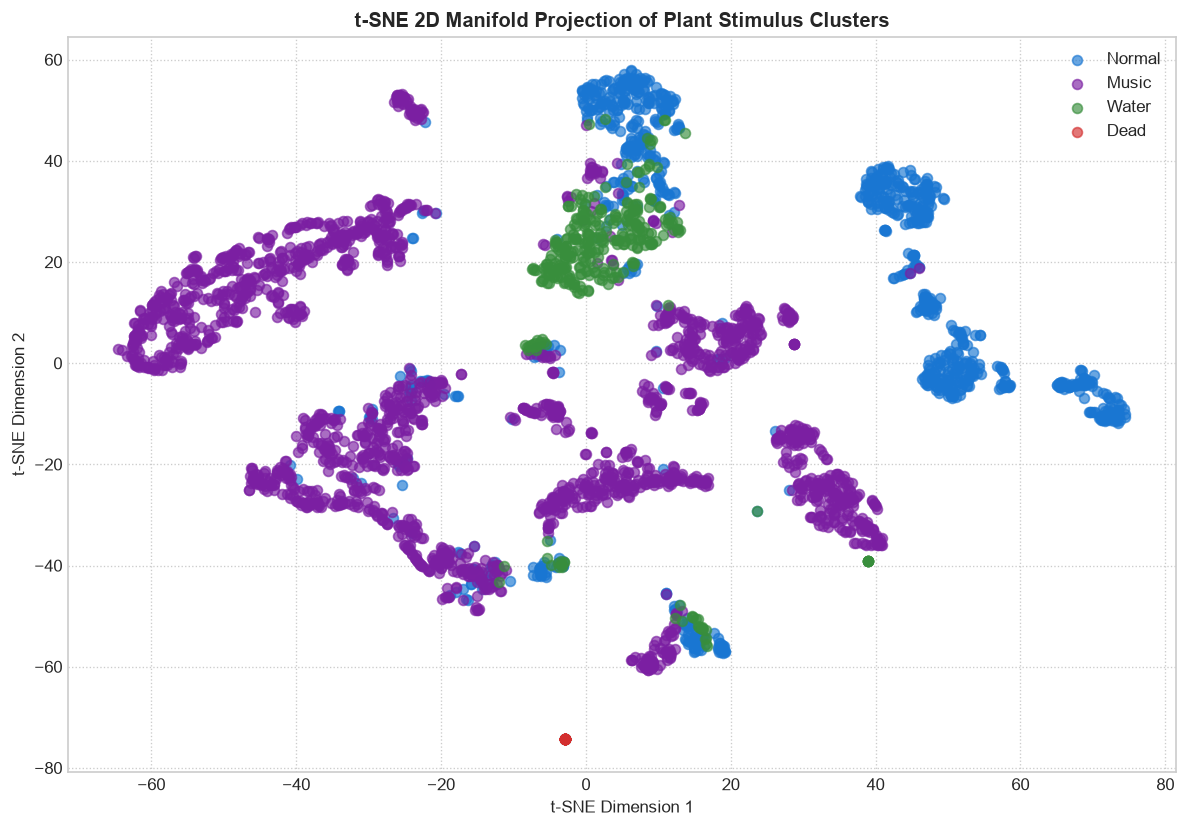

In [6]:
tsne = TSNE(n_components=2, perplexity=35, random_state=42, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

plt.figure(figsize=(10, 7))
palette = {"normal": "#1976D2", "music": "#7B1FA2", "water": "#388E3C", "dead": "#D32F2F"}

for c_name in class_labels:
    idx = (df["main_category"] == c_name).values
    plt.scatter(X_tsne[idx, 0], X_tsne[idx, 1], label=c_name.capitalize(), color=palette[c_name], alpha=0.65, s=35)

plt.title("t-SNE 2D Manifold Projection of Plant Stimulus Clusters", fontweight='bold')
plt.xlabel("t-SNE Dimension 1")
plt.ylabel("t-SNE Dimension 2")
plt.legend(framealpha=0.9, loc="upper right")
plt.grid(True, linestyle=':')
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "3_tsne_manifold_clusters.png"), dpi=300, bbox_inches='tight')
plt.show()


## 7. KNN Hyperparameter Optimization

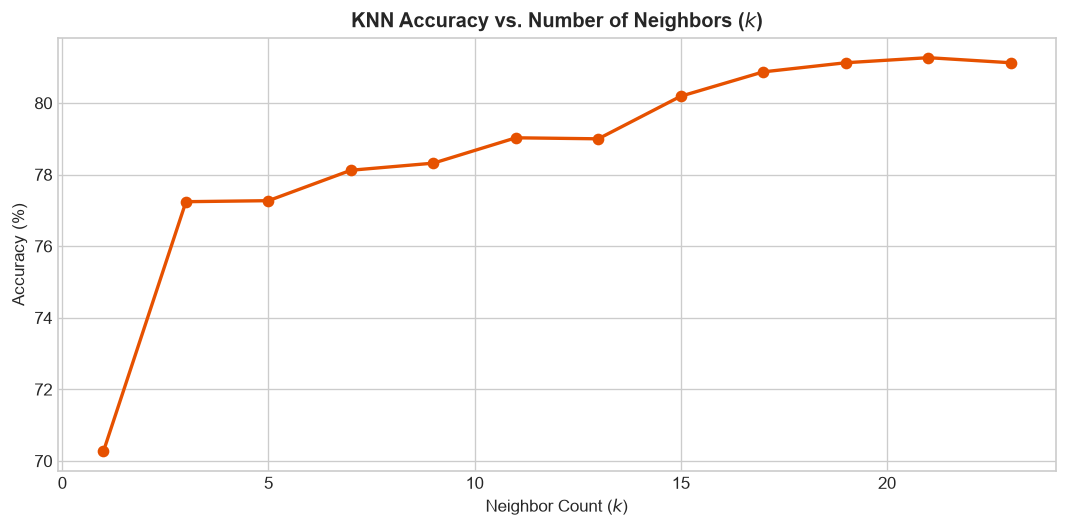

In [7]:
k_range = range(1, 25, 2)
k_scores = []

for k in k_range:
    knn_temp = KNeighborsClassifier(n_neighbors=k, weights='distance')
    preds = cross_val_predict(knn_temp, X_scaled, y, cv=3)
    k_scores.append(np.mean(preds == y))

plt.figure(figsize=(9, 4.5))
plt.plot(k_range, [s*100 for s in k_scores], marker='o', color='#E65100', lw=2)
plt.title("KNN Accuracy vs. Number of Neighbors ($k$)", fontweight='bold')
plt.xlabel("Neighbor Count ($k$)")
plt.ylabel("Accuracy (%)")
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "4_knn_k_tuning.png"), dpi=300, bbox_inches='tight')
plt.show()
